# Stage 1: Screening


The main question of the screening stage is to identify which levers have a significant effect on the KPIs and which combinations of levers are non-dominated. 

= 32 combinations of the five levers (L2, L3, L4, L5, L6) at two levels (-1 = off, +1 = on).  with R = 5 replications for each combination and shock level. The first five seeds from the screening pool are used for all runs to ensure consistency.

**Screening plan:**
* The screening stage uses a full factorial design 2⁵=32 with L2, L3, L4, L5, L6 as factors
* Each combination is tested at three levels of `shock depth` (0.2, 0.45, 0.7)
* We have R = 5 replications for each combination and shock level, using the first five seeds from the screening pool. We use replications since the model is stochastic, and we want to estimate the mean and variance of the KPIs for each combination. The first five seeds are used to ensure that the runs are consistent across different combinations and shock levels.
* The order of runs is randomized to avoid any systematic biases.
* +5 additional runs for the baseline P0 (no measures, nominal uncertainty, three levels of shock) to normalize the KPIs.

```
32 factorial × 3 shock ×  5 replications + 5 baseline = 485 runs
```

## 1.0. Environment setup

In [1]:
import json, hashlib, itertools, math, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy import stats

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import abm_runner as ar

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=PAL)})


The notebook uses the `prep_summary.json` file to check that the model hash has not changed since the preparation stage and to read the constants, seed, horizon, R, processes, and plan for the screening stage.

In [2]:
NETLOGO_HOME = r"C:\Program Files\NetLogo 7.0.4"
MODEL_PATH   = Path("refinery_shock_abm.nlogox")
OUT_DIR      = Path("results")


# preparation results from stage 0
PREP  = json.loads((OUT_DIR / "prep_summary.json").read_text(encoding="utf-8"))

# Load the seeds generated in stage 0
SEEDS = json.loads((OUT_DIR / "seeds.json").read_text(encoding="utf-8"))["pools"]

# check if the model file has not changed since stage 0
sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
assert sha == PREP["model_sha256"], "File changed"
print("The same model as in stage 0:", sha[:16], "| NetLogo", PREP["netlogo_version"])

The same model as in stage 0: 2b246166dc0c1182 | NetLogo 7.0.4


In [3]:
R          = 5  # replications per shock level
SCR_SEEDS  = SEEDS["screening"][:R]
SHOCKS     = PREP["shock_levels"]                     
LEVER_ON   = PREP["lever_on"]
SWITCH     = {"L2": "L2-export-ban?", "L3": "L3-quality-relax?", "L4": "L4-import?",
              "L5": "L5-fillup-limit?", "L6": "L6-price-cap?"}
LEVERS     = list(SWITCH)
KPIS       = ["K0", "K0@90", "K1", "K2", "K3_volume", "K4", "K5_hours"]
N_CARS     = PREP["constants"]["n-consumers"]
D0         = PREP["constants"]["D0"]
ETA2_MIN   = 0.05  # the minimum value of the uncertain parameter eta2                                    

print("scrining seed :", SCR_SEEDS)

scrining seed : [347, 164, 159, 797, 98]


In [4]:
# JVM arguments for the Java Virtual Machine
# -Xmx512m sets the maximum heap size to 512 megabytes
JVM_ARGS = ["-Xmx512m"]    
CFG = {"netlogo_home": NETLOGO_HOME, "model_path": str(MODEL_PATH.resolve()), "jvmargs": JVM_ARGS,
       "jvm_path": ar.find_jvm(NETLOGO_HOME), "horizon": PREP["horizon"], "checkpoints": PREP["checkpoints"],
       "interface_defaults": PREP["interface_defaults"], "nominal_uncertain": PREP["nominal_uncertain"]}


## 1.1. Preparation of the design matrix

32 combinations of the five levers (L2, L3, L4, L5, L6) at two levels (-1 = off, +1 = on) are generated using `itertools.product`. The design matrix X is created with a column of ones for the intercept and columns for each lever. The design matrix is then checked for orthogonality to ensure that the main effects and pairwise interactions are not confounded. 


Note: during the screening stage we only set 0/1 for the levers, as we only need to identify which levers have a significant effect on the KPIs. The actual values of the levers will be set in the later stages of the experiment.

In [8]:
def combo_name(bits):
    
    """
    This function takes a list of bits (0s and 1s) as string representing the state of levers
    and returns a string that represents the combination of levers that are turned on.
    If no levers are on, it returns "none".
    
    Parameters:
        bits (list): A list of bits (0s and 1s) representing the state of levers.
    
    Returns:
        str: A string representing the combination of levers that are turned on.
    
    """
    
    
    on = [l for l, b in zip(LEVERS, bits) if b]
    return "+".join(on) if on else "none"


def make_job(bits, shock, seed, rep, stage="screening"):
    
    """
    This function creates a job dictionary for a given combination of levers,
    shock depth, seed, replication number, and stage.
    
    Parameters:
        bits (tuple): A tuple of bits (0s and 1s) representing the state of levers.
        shock (float): The shock depth for the job.
        seed (int): The seed for the job.
        rep (int): The replication number for the job.
        stage (str): The stage of the job (default is "screening").
    
    Returns:
        dict: A dictionary containing job information, including
            run_id,
            stage,
            design_id,
            code,
            shock,
            seed,
            rep,
            lever states,
            parameters,
            uncertain values

    """
    
    
    
    params = {SWITCH[l]: bool(b) for l, b in zip(LEVERS, bits)} | LEVER_ON | {
        "L4-subsidy": PREP["interface_defaults"]["L4-subsidy"], "shock-depth": shock}
    name = combo_name(bits)
    return {"run_id": f"{stage}|{name}|sd={shock}|seed={seed}", "stage": stage, "design_id": name,
            "code": "".join(map(str, bits)), "shock": shock, "seed": int(seed), "rep": rep,
            **{l: (1 if b else -1) for l, b in zip(LEVERS, bits)}, "params": params, "uncertain": None}

# create jobs for the background runs (no levers, no shock)
COMBOS = list(itertools.product([0, 1], repeat=5))
JOBS = [make_job((0,) * 5, 0.0, s, r, stage="background")
        for r, s in enumerate(SCR_SEEDS, 1)]

# create jobs for each combination of levers, shock depth, and seed 
for r, s in enumerate(SCR_SEEDS, 1):
    for sh in SHOCKS:
        for bits in COMBOS:
            JOBS.append(make_job(bits, sh, s, r))

# write the design matrix to a CSV file
DESIGN = pd.DataFrame(
    [{k: v for k, v in j.items() if k not in ("params", "uncertain")} for j in JOBS])
DESIGN.to_csv(OUT_DIR / "design_screening.csv",
              index=False, encoding="utf-8-sig")
assert DESIGN.run_id.is_unique
X = DESIGN.query(
    "stage == 'screening' and rep == 1 and shock == @SHOCKS[0]")[LEVERS].to_numpy()
assert np.allclose(X.T @ X, 32 * np.eye(5)), "design is not orthogonal"
print(f"jobs: {len(JOBS)} (design {len(JOBS) - R} + background {R})")
DESIGN.head(8)

jobs: 485 (design 480 + background 5)


,run_id,stage,design_id,code,shock,seed,rep,L2,L3,L4,L5,L6
0,background|none|sd=0.0|seed=347,background,none,00000,0.0,347,1,-1,-1,-1,-1,-1
1,background|none|sd=0.0|seed=164,background,none,00000,0.0,164,2,-1,-1,-1,-1,-1
2,background|none|sd=0.0|seed=159,background,none,00000,0.0,159,3,-1,-1,-1,-1,-1
3,background|none|sd=0.0|seed=797,background,none,00000,0.0,797,4,-1,-1,-1,-1,-1
4,background|none|sd=0.0|seed=98,background,none,00000,0.0,98,5,-1,-1,-1,-1,-1
5,screening|none|sd=0.2|seed=347,screening,none,00000,0.2,347,1,-1,-1,-1,-1,-1
6,screening|L6|sd=0.2|seed=347,screening,L6,00001,0.2,347,1,-1,-1,-1,-1,1
7,screening|L5|sd=0.2|seed=347,screening,L5,00010,0.2,347,1,-1,-1,-1,1,-1


## 1.2. Parallel execution of the runs

During the screening stage, we will run the 485 runs in parallel using a pool of worker processes. The number of worker processes can be set using the `N_WORKERS` variable. The runs will be distributed among the workers, and each worker will execute its assigned runs sequentially.

В этапе 0 тест сравнивал пул с одним быстрым прогоном (8.2 с), а средний прогон в процессе ноутбука - 22 с. Пересчёт того же теста: 4 процесса давали ~385 прогонов/ч против ~164 в одиночку, то есть пул всё-таки ускорял в ~2.3 раза.

Здесь тест честный: 8 заданий (4 комбинации × 2 seed пилота), время которых в одиночном режиме уже известно из `pilot.csv`. Для 2, 3, 4 процессов считаем пропускную способность в установившемся режиме (`число процессов × 3600 / среднее время прогона в пуле`) и сравниваем с одиночной на тех же заданиях. Заодно проверяем, что результаты в пуле совпадают с пилотом (воспроизводимость между процессами).

**Перед запуском:** закрыть браузер и тяжёлые программы, ноутбук на зарядке. Java в процессе ноутбука на этом шаге не запускается. Тест займёт ~8-10 мин; ячейку можно пропустить и задать `N_WORKERS` вручную в следующей.

In [6]:
import importlib
import batch_runner as br
importlib.reload(br)

<module 'batch_runner' from 'c:\\Users\\arsmi\\Downloads\\netlogo-project\\Experiments\\batch_runner.py'>

In [8]:
# ! WARNING This cell takes approximately 10 minutes to run

import psutil
# psutil is a cross-platform library for retrieving information
# on running processes and system utilization
# (CPU, memory, disks, network, sensors)
vm = psutil.virtual_memory()
print(f"physical cores: {psutil.cpu_count(logical=False)}, RAM available {vm.available / 2**30:.1f} of {vm.total / 2**30:.1f} GB")

PILOT = br.read_results(OUT_DIR / "pilot.csv")
pilot_map = {"P0": (0, 0, 0, 0, 0), "P1": (0, 1, 0, 1, 1), "P2": (1, 0, 1, 0, 0), "ALL": (1, 1, 1, 1, 1)}
test_seeds = SEEDS["pilot"][:2]
ref = PILOT[PILOT.seed.isin(test_seeds)].groupby(["design_id", "seed"]).mean(numeric_only=True)

test_rows = []
for n in [2, 3, 4]:
    if psutil.virtual_memory().available / 2**30 < 0.7 * n:
        print(f"{n} processes: not enough free memory, skipping"); continue
    tjobs = []
    for pid, bits in pilot_map.items():
        for s in test_seeds:
            j = make_job(bits, PREP["shock_mid"], s, 0, stage="ptest")
            j["run_id"] += f"|w{n}"; j["pilot_id"] = pid
            tjobs.append(j)
    out = OUT_DIR / f"_pool_test_w{n}.csv"
    out.unlink(missing_ok=True)
    t0 = time.perf_counter()
    res = br.run_jobs(tjobs, CFG, out, n_workers=n, log_every=30, resume=False)
    wall = time.perf_counter() - t0
    single = np.mean([ref.loc[(p, s), "sec"] for p, s in zip(res.pilot_id, res.seed)])
    same = all(np.isclose(r.K0, ref.loc[(r.pilot_id, r.seed), "K0"], rtol=1e-9) and
               np.isclose(r.K4, ref.loc[(r.pilot_id, r.seed), "K4"], rtol=1e-9) for r in res.itertuples())
    test_rows.append({"processes": n, "s/run in pool": res.sec.mean(), "s/run single": single,
                      "runs/h (pool)": n * 3600 / res.sec.mean(), "runs/h (single)": 3600 / single,
                      "speedup": n * single / res.sec.mean(), "min per test": wall / 60,
                      "matches pilot": same})
    out.unlink(missing_ok=True)
POOL_TEST = pd.DataFrame(test_rows)
POOL_TEST.round(2)

physical cores: 4, RAM available 1.5 of 15.8 GB
15:07:27 start: 8 runs, workers: 2
15:07:58 ... working, 0/8
15:08:28 ... working, 0/8
15:08:58 ... working, 0/8
15:09:09 1/8 | 2 min | 35 runs/h | ETA ~12 min | errors 0
15:09:40 ... working, 2/8
15:09:49 3/8 | 2 min | 76 runs/h | ETA ~4 min | errors 0
15:10:24 7/8 | 3 min | 143 runs/h | ETA ~0 min | errors 0
15:10:24 8/8 | 3 min | 163 runs/h | ETA ~0 min | errors 0
15:10:24 done: 8 in 2.9 min, errors 0
3 processes: not enough free memory, skipping
4 processes: not enough free memory, skipping


,processes,s/run in pool,s/run single,runs/h (pool),runs/h (single),speedup,min per test,matches pilot
0,2,30.48,29.02,236.22,124.04,1.9,2.94,True


In [ ]:
# choice: best option if speedup is at least 1.3; otherwise a single process
if len(POOL_TEST) and POOL_TEST["speedup"].max() >= 1.3:
    best = POOL_TEST.loc[POOL_TEST["speedup"].idxmax()]
    N_WORKERS, RUNS_PER_HOUR = int(best["processes"]), float(best["runs/h (pool)"])
else:
    N_WORKERS, RUNS_PER_HOUR = 1, 3600 / 22
# N_WORKERS, RUNS_PER_HOUR = 3, 380      # <- manual setting if the test was skipped
print(f"N_WORKERS = {N_WORKERS}, ~{RUNS_PER_HOUR:.0f} runs/h -> 485 runs in ~{485 / RUNS_PER_HOUR:.1f} h")

N_WORKERS = 2, ~349 прогонов/ч -> 485 прогонов за ~1.4 ч


## 1.3. Launching the runs

The results of the runs will be saved in the `results/screening.csv` file. Each run will be executed using the `run_id`, which is a unique identifier for each run. The `run_id` is generated based on the combination of levers, shock depth, seed, and replication number.


In [ ]:
# ! WARNING This cell takes approximately 3 hours to run
link = ar.make_link(CFG) if N_WORKERS == 1 else None
RES = br.run_jobs(JOBS, CFG, OUT_DIR / "screening.csv", n_workers=N_WORKERS, link=link, log_every=60)
print(RES.groupby("stage").size())

16:33:03 старт: 485 прогонов, процессов: 2
16:34:11 3/485 | 1 мин | 159 прогонов/ч | осталось ~182 мин | ошибок 0
16:35:27 9/485 | 2 мин | 225 прогонов/ч | осталось ~127 мин | ошибок 0
16:36:37 15/485 | 4 мин | 253 прогонов/ч | осталось ~112 мин | ошибок 0
16:37:43 23/485 | 5 мин | 296 прогонов/ч | осталось ~94 мин | ошибок 0
16:38:45 31/485 | 6 мин | 327 прогонов/ч | осталось ~83 мин | ошибок 0
16:39:49 39/485 | 7 мин | 347 прогонов/ч | осталось ~77 мин | ошибок 0
16:41:01 45/485 | 8 мин | 339 прогонов/ч | осталось ~78 мин | ошибок 0
16:42:15 49/485 | 9 мин | 320 прогонов/ч | осталось ~82 мин | ошибок 0
16:43:25 54/485 | 10 мин | 313 прогонов/ч | осталось ~83 мин | ошибок 0
16:44:35 59/485 | 12 мин | 307 прогонов/ч | осталось ~83 мин | ошибок 0
16:45:48 65/485 | 13 мин | 306 прогонов/ч | осталось ~82 мин | ошибок 0
16:47:23 71/485 | 14 мин | 297 прогонов/ч | осталось ~84 мин | ошибок 0
16:48:37 74/485 | 16 мин | 285 прогонов/ч | осталось ~86 мин | ошибок 0
16:49:38 78/485 | 17 мин | 2

## 1.4. Check for completeness and reproducibility

* all 485 tasks completed, no errors
* 15 runs of 'none' match the runs of stage 0 (`baseline_P0.csv`) - the model, seed, and connection to NetLogo yield the same result on a different day and in a different process;
* run time by combinations - will be useful for the budget of stages 2-3.

In [9]:
RES = br.read_results(OUT_DIR / "screening.csv")
missing = set(DESIGN.run_id) - set(RES.run_id)
print(f"calculated {RES.run_id.isin(DESIGN.run_id).sum()} out of {len(DESIGN)}, missing {len(missing)}")
err_file = OUT_DIR / "screening.errors.csv"
print("error file:", "exists - check it" if err_file.exists() else "does not exist")


calculated 485 out of 485, missing 0
error file: does not exist


In [10]:
# check that the baseline results match the 'none' design in the screening stage
BASE0 = br.read_results(OUT_DIR / "baseline_P0.csv")
chk = RES.query("design_id == 'none' and stage == 'screening'").merge(
    BASE0[["shock", "seed", "K0", "K1", "K4", "K5_hours"]], on=["shock", "seed"], suffixes=("", "_b0"))
ok = all(np.allclose(chk[k], chk[k + "_b0"], rtol=1e-9) for k in ["K0", "K1", "K4", "K5_hours"])
print(f"match 'none' with stage 0: {ok} ({len(chk)} runs)")

# analyze the screening results
SCR = RES[RES.stage == "screening"].copy()
BG = RES[RES.stage == "background"].copy()
print(f"run time: average {SCR.sec.mean():.1f} s, median {SCR.sec.median():.1f} s")
SCR.groupby("design_id").sec.mean().sort_values(ascending=False).head(6).round(1)

match 'none' with stage 0: True (15 runs)
run time: average 22.5 s, median 20.1 s


design_id
L5+L6          34.5
L3+L5+L6       33.0
L4+L5+L6       31.4
L2+L3+L5+L6    29.4
L2+L5+L6       28.4
L6             27.2
Name: sec, dtype: float64

## 1.5. Analysis of the screening results

* `K5_excess` displays the queues above the background without a shock, time on the machine: K5 at the background is almost the same as at 'none' with a weak and moderate shock, so we compare what the shock and levers add;
* `K2` is recalculated for any subsidy: K2 = L4-subsidy × import volume, import volume = K2 / 0.25;
* for analysis we use `log(1 + K)` since the effects of the levers are multiplicative, and the spread between combinations varies by orders of magnitude (in the pilot - by 80 times for K0).

In [19]:
K5_BG = BG.K5_hours.mean()
SCR["K5_excess"] = (SCR.K5_hours - K5_BG) / N_CARS
SCR["import_volume"] = SCR.K2 / PREP["interface_defaults"]["L4-subsidy"]

print(
    f"background K5 without shock: {K5_BG:.0f} machine-hours per year ({K5_BG / N_CARS:.2f} h/machine)")

# log-transform the KPIs for better visualization and analysis
RESP = KPIS
for k in RESP:
    SCR["log_" + k] = np.log1p(SCR[k].clip(lower=0))

# create a summary table of the screening results
# grouping by shock, design_id, and code
# calculating the mean of the KPIs and other relevant metrics
CELL = SCR.groupby(["shock", "design_id", "code"] + LEVERS)[KPIS +
                                                            ["K5_excess", "import_volume", "price", "sec"]].mean().reset_index()
CELL.to_csv(OUT_DIR / "screening_cells.csv", index=False, encoding="utf-8-sig")
CELL.query("shock == 0.45").sort_values("K0").head(10).round(2)

background K5 without shock: 13675 machine-hours per year (2.74 h/machine)


,shock,design_id,code,L2,L3,L4,L5,L6,K0,K0@90,K1,K2,K3_volume,K4,K5_hours,K5_excess,import_volume,price,sec
34,0.45,L2+L3+L4,11100,1,1,1,-1,-1,1118.94,1117.93,267914.10,122725.92,411653.3,1543868.92,13668.67,-0.00,490903.69,1.23,20.11
33,0.45,L2+L3,11000,1,1,-1,-1,-1,1651.59,1620.98,445698.00,0.00,411653.3,2854242.60,16160.16,0.50,0.00,1.47,13.98
37,0.45,L2+L3+L4+L6,11101,1,1,1,-1,1,1924.64,1921.78,97955.16,124544.98,411653.3,515471.30,16178.21,0.50,498179.92,1.10,17.78
35,0.45,L2+L3+L4+L5,11110,1,1,1,1,-1,2206.10,2204.68,243275.98,122993.32,411653.3,1383459.92,57907.26,8.85,491973.29,1.25,18.11
36,0.45,L2+L3+L4+L5+L6,11111,1,1,1,1,1,2413.03,2405.55,95835.51,124695.84,411653.3,504153.96,65565.27,10.38,498783.36,1.10,16.19
41,0.45,L2+L4,10100,1,-1,1,-1,-1,2469.66,2458.39,336075.66,123165.54,0.0,2043374.70,13802.62,0.03,492662.15,1.31,17.80
50,0.45,L3+L4+L5,1110,-1,1,1,1,-1,2645.00,2644.07,271032.82,124067.23,411653.3,1565617.50,60924.43,9.45,496268.90,1.27,25.11
42,0.45,L2+L4+L5,10110,1,-1,1,1,-1,2666.12,2660.35,288075.07,124542.08,0.0,1681065.50,61772.93,9.62,498168.33,1.29,20.43
49,0.45,L3+L4,1100,-1,1,1,-1,-1,2795.40,2788.09,316311.82,122770.79,411653.3,1895868.57,13794.47,0.02,491083.15,1.26,23.41
51,0.45,L3+L4+L5+L6,1111,-1,1,1,1,1,3023.48,3008.16,96178.20,125458.25,411653.3,506013.73,69953.86,11.26,501832.99,1.10,27.05


## 1.6. Statistical analysis

For each KPI and each shock level, we fit a linear model of the form: `log(1+K) ~ (L2+L3+L4+L5+L6)**3 + C(seed)` in order to estimate the main effects and interaction terms of the levers on the KPIs. We use 2⁵ combinations of levers × R = 5 = 160 runs. 

Formula explanation:

* `log(1+K)` is the response variable, where K is the KPI of interest. We use the logarithm to stabilize the variance and make the effects of the levers additive
* `(L2+L3+L4+L5+L6)**3` represents the main effects and all pairwise and three-way interactions of the levers. In statsmodels, (A + B + C)**3 means the following: we include all main effects (A, B, C), all pairwise interactions (AB, AC, BC), and all three-way interactions (ABC). Why limit to three-way interactions? Higher-order interactions are often difficult to interpret and may not be significant
* `C(seed)` is a categorical variable that accounts for the random seed used in the runs. This allows us to control for the variability introduced by the stochastic nature of the model and to estimate the main effects and interactions of the levers more accurately.

Effect of the lever on the KPI is 2β since the lever is coded as -1 and +1. The main effect of a lever is the average change in the KPI when the lever is turned on versus off, while holding all other levers constant. The interaction effect between two levers is the additional change in the KPI when both levers are turned on, beyond what would be expected from their individual main effects.

η² is a measure of effect size that represents the proportion of variance in the response variable that is explained by a particular factor or interaction. **A higher η² value indicates a stronger effect of the factor on the response variable.**


We use ANOVA to test the significance of the main effects and interaction terms. ANOVA is a statistical method that checks the significance of the main effects and interaction terms in a linear model. **ANOVA allows us to determine whether the effect of a lever or interaction is statistically significant.**



In the following code, we fit the linear model for each KPI and each shock level, and then perform ANOVA to test the significance of the main effects and interaction terms. The results of the ANOVA are stored in a dictionary for further analysis.

In [15]:
FORMULA = "y ~ (L2 + L3 + L4 + L5 + L6)**3 + C(seed)"
rows, MODELS = [], {}
for sh in SHOCKS:  # iterate over 3 shock levels
    d = SCR[SCR.shock == sh]  # every shock level has 160 runs
    for k in RESP:  # iterate over each KPI

        # log-transform the KPI for better visualization and analysis
        y = d["log_" + k]
        if y.std() < 1e-12:
            continue

        # Fit the linear model using ordinary least squares (OLS) regression
        m = smf.ols(FORMULA, data=d.assign(y=y)).fit()
        MODELS[(sh, k)] = m

        # Perform ANOVA to test the significance
        # of the main effects and interaction terms
        an = sm.stats.anova_lm(m, typ=2)

        # Calculate the sum of squares for the residuals
        # Later used for η² for each term in the model
        ss_res = an.loc["Residual", "sum_sq"]

        for term in an.index:
            if term in ("Residual", "C(seed)"):
                continue
            # the effect of the lever or interaction term on the KPI
            beta = m.params[term]

            # add the results to the table of effects
            rows.append({"shock": sh,
                         "KPI": k,
                         "term": term.replace(":", "×"),
                         "order": term.count(":") + 1,
                         # shows the effect of the lever on the KPI in log scale
                         "effect_log": 2 * beta,
                         # shows the effect of the lever on the KPI in percentage
                         "effect_%": 100 * (np.exp(2 * beta) - 1),
                         # shows the 95% confidence interval for the effect of the lever on the KPI in percentage
                         "ci95_%": 100 * (np.exp(2 * 1.96 * m.bse[term]) - 1),
                         "eta2_partial": an.loc[term, "sum_sq"] / (an.loc[term, "sum_sq"] + ss_res),
                         "p": an.loc[term, "PR(>F)"]})

# save the effects table to a CSV file for further analysis
EFFECTS = pd.DataFrame(rows)
EFFECTS.to_csv(OUT_DIR / "screening_effects.csv",
               index=False, encoding="utf-8-sig")

R^2 is a measure of how well the linear model fits the data. It represents the proportion of variance in the response variable that is explained by the model. A higher R² value indicates a better fit of the model to the data.


R^2 ~ 1.0 - the KPI is almost completely determined by the levers and the seed, and the residual variance is small. This means that the model is able to explain most of the variability in the KPI based on the levers and seed used in the runs.

R^2 lower than 1.0 - the KPI is influenced by other factors not included in the model, and the residual variance is larger. This means that the model is not able to explain all of the variability in the KPI based on the levers and seed used in the runs.

In [12]:

# look at how much variance in the KPI is explained by the levers and seed
R2 = pd.DataFrame({f"{sh}": {k: MODELS[(sh, k)].rsquared for k in RESP if (
    sh, k) in MODELS} for sh in SHOCKS})
print("R² of models (proportion of variance explained by levers and seed):")
display(R2.round(3))


R² of models (proportion of variance explained by levers and seed):


,0.2,0.45,0.7
K0,0.899,0.969,0.978
K0@90,0.828,0.949,0.953
K1,0.991,0.995,0.998
K2,1.000,1.000,1.000
K3_volume,1.000,1.000,1.000
K4,0.990,0.995,0.998
K5_hours,0.965,0.979,0.994


K1 and K4 have almost identical R^2 values
* 0.2 shock: 0.991 and 0.99
* 0.45 shock: 0.995 both
* 0.7 shock: 0.998 both

It means that K1 and K4 are almost completely determined by the levers and the seed, and the residual variance is small. This is expected since K1 and K4 are both determined by price. Two nearly identical axes add no information but increase the number of non-dominated points. We will consider that in the next stage of the experiment

In [25]:
# correlation across 32 screening combinations
SCR.groupby(["shock", "design_id"])[["log_K1", "log_K4"]].mean() \
   .groupby("shock").corr().loc[(slice(None), "log_K1"), "log_K4"]

shock        
0.20   log_K1    0.999446
0.45   log_K1    0.998279
0.70   log_K1    0.998385
Name: log_K4, dtype: float64

We will sort the results by η²_partial in descending order and display the top 10 effects to do a quick check of the results for shock = 0.45 and KPI = 'K0' and see which levers have the most significant effect on the KPI. 

In [13]:
EFFECTS.query("shock == 0.45 and KPI == 'K0'").sort_values(
    "eta2_partial", ascending=False).head(10).round(3)

,shock,KPI,term,order,effect_log,effect_%,ci95_%,eta2_partial,p
179,0.45,K0,L6,1,2.598,1243.342,13.954,0.921,0.0
177,0.45,K0,L4,1,-2.125,-88.060,13.954,0.887,0.0
176,0.45,K0,L3,1,-1.479,-77.222,13.954,0.791,0.0
175,0.45,K0,L2,1,-1.248,-71.286,13.954,0.729,0.0
188,0.45,K0,L4×L6,2,-1.175,-69.108,13.954,0.705,0.0
197,0.45,K0,L3×L4×L6,3,-0.522,-40.681,13.954,0.321,0.0
186,0.45,K0,L3×L6,2,-0.452,-36.377,13.954,0.262,0.0
194,0.45,K0,L2×L4×L6,3,-0.441,-35.631,13.954,0.252,0.0
190,0.45,K0,L2×L3×L4,3,0.410,50.692,13.954,0.226,0.0
183,0.45,K0,L2×L6,2,-0.323,-27.575,13.954,0.153,0.0


ci95_% is the same (13.954) for all levers, which is convenient for comparing the effects of the levers. The main effects of the levers on K0 are as follows:

* L6 (Price-cap) effect_% = +1243%, worsens K0 
* L4 (Subsidy) effect_%  = -88%, best way to improve K0 in this scenario
* At the same L4×L6 (η²=0.705) is as important as other factors, which means that L4 should not be considered in isolation
* L3 (quality-relax) and L2 (export-ban) effect_% = −77% and −71% respectively
* η² for triple interactions: L3×L4×L6 (0.321), L2×L4×L6 (0.252), L2×L3×L4 (0.226). That means that the effect of these interactions is significant and should be considered when designing the policy

## 1.7. Pareto analysis of the screening results

For each KPI, we will create a Pareto chart that shows the main effects and interaction terms of the levers on the KPI. The Pareto chart will display the η² partial values for each effect, sorted in descending order. The chart will also include a horizontal line at the 0.05 significance level to indicate which effects are statistically significant.

The longer the bar, the more important the effect of the lever or interaction on the KPI. Orange bars increase the KPI, while blue bars decrease the KPI


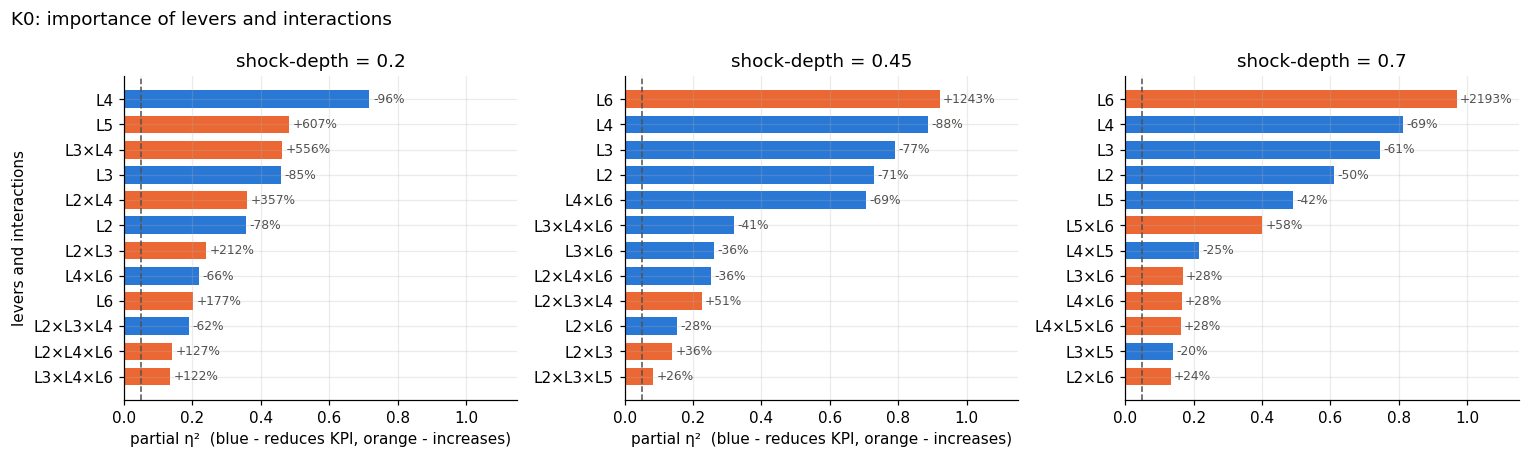

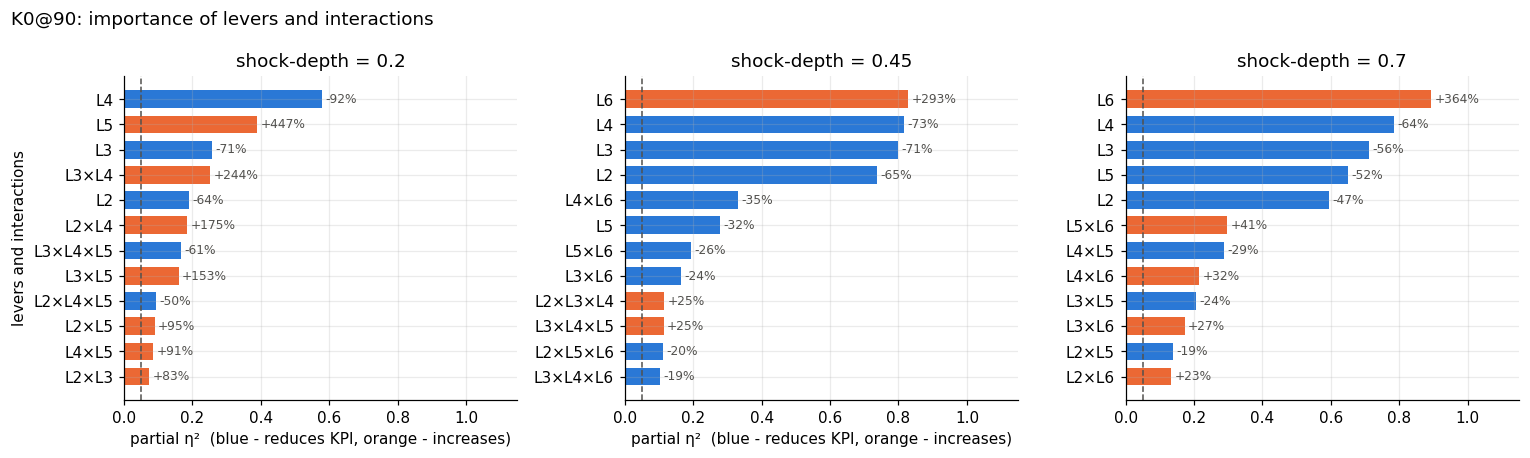

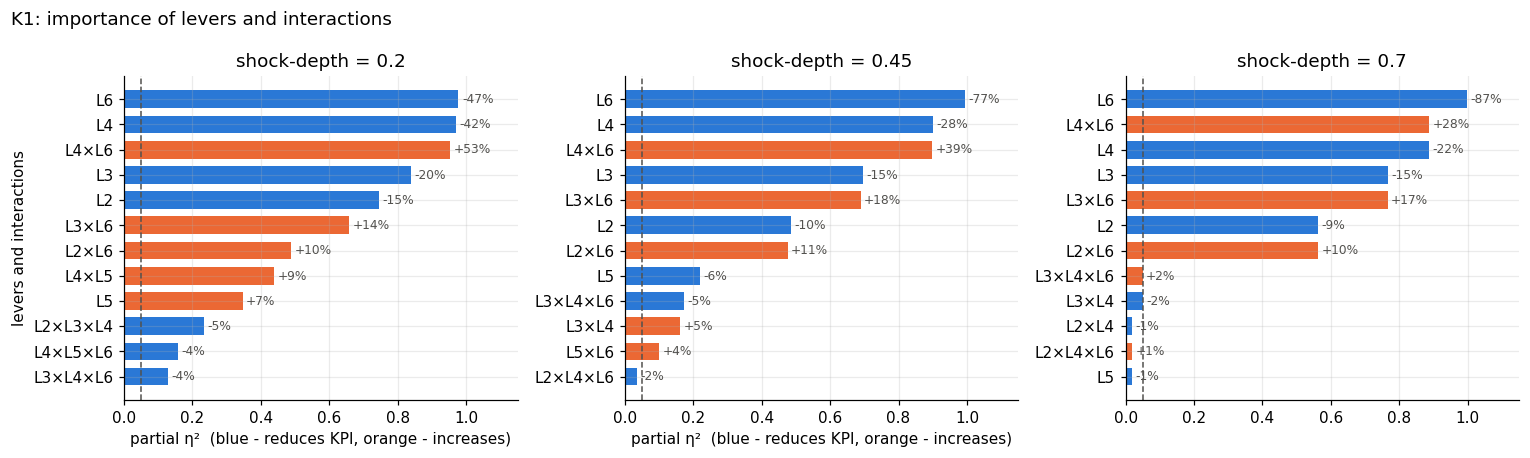

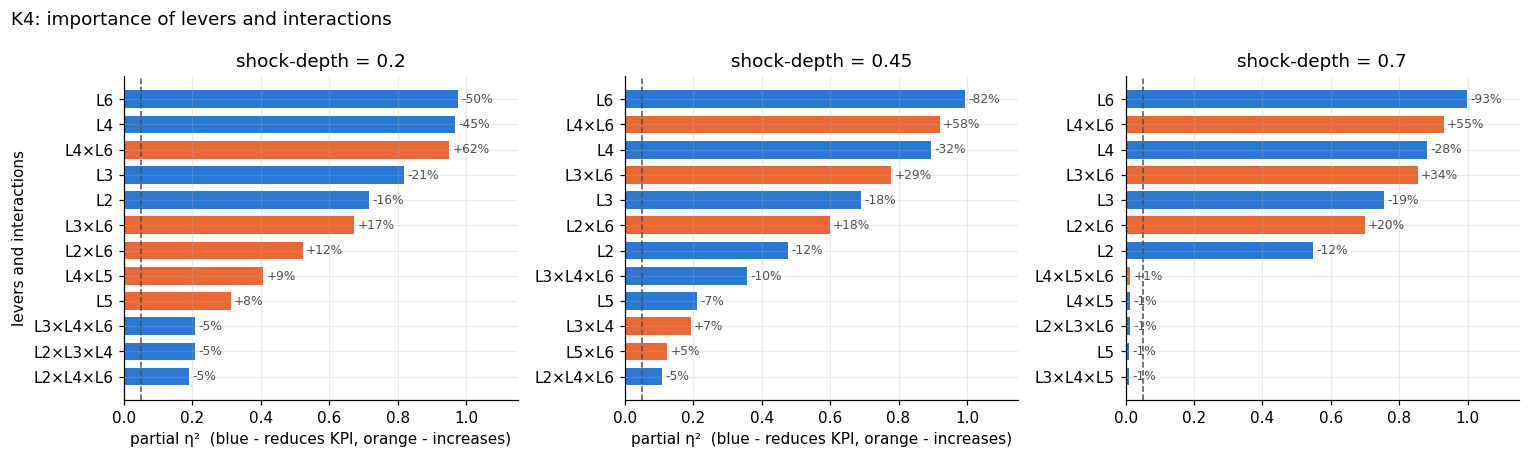

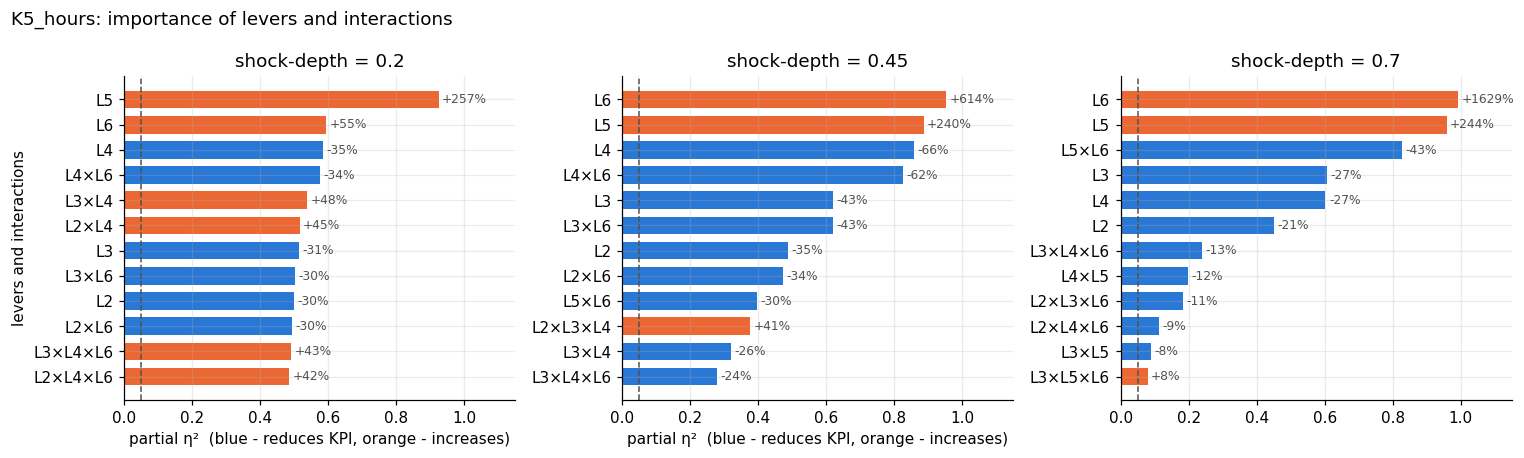

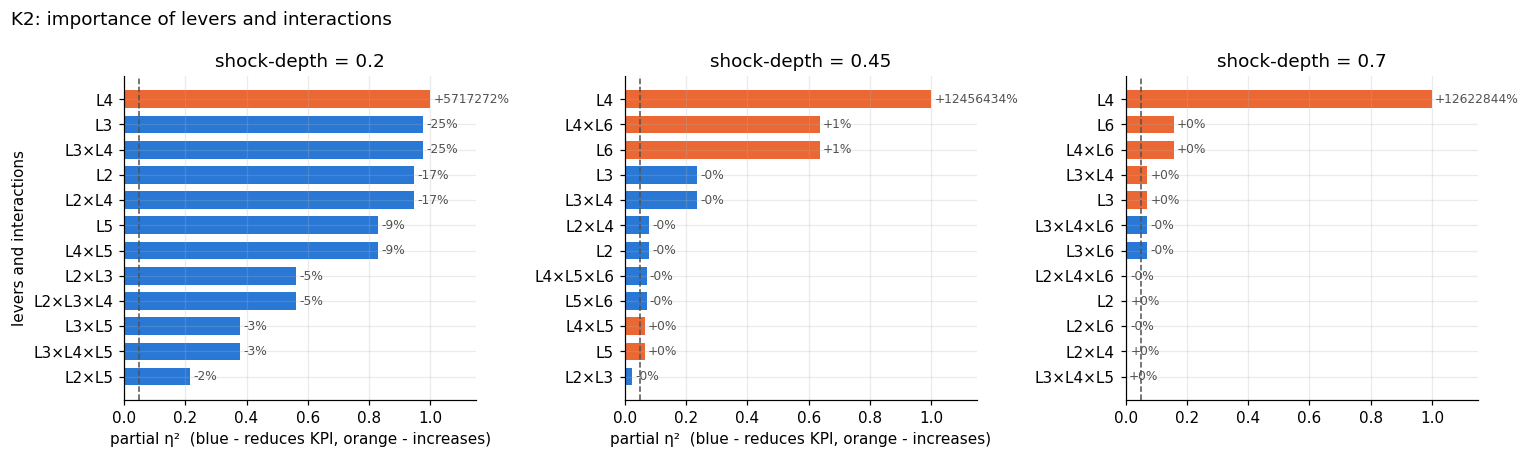

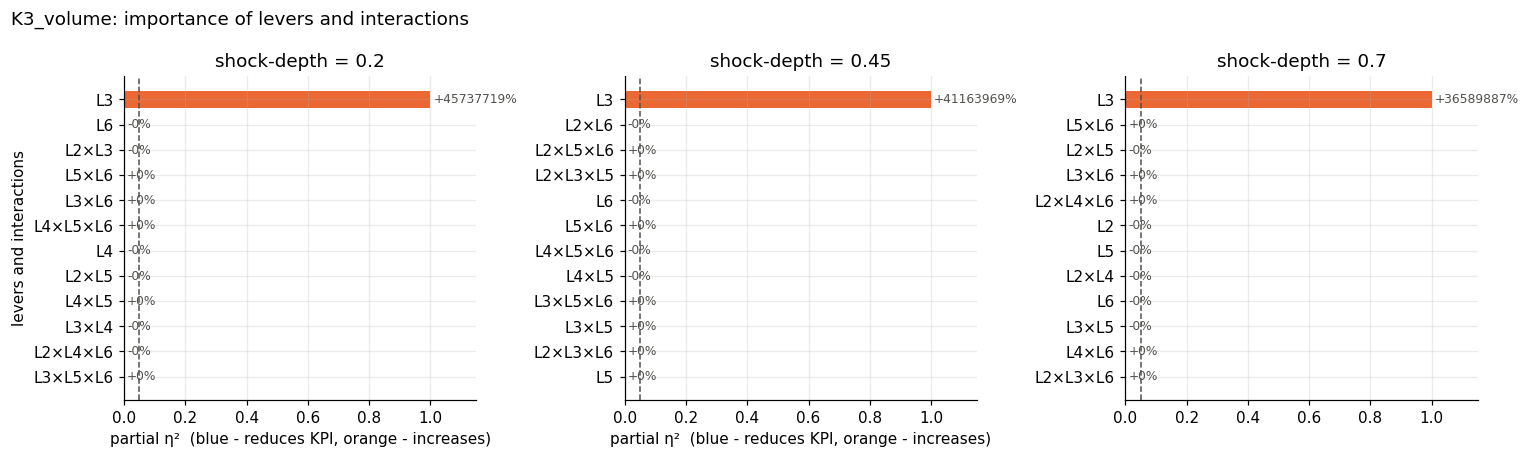

In [ ]:
def pareto_effects(kpi, top=12):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
    for ax, sh in zip(axes, SHOCKS):
        e = EFFECTS.query("KPI == @kpi and shock == @sh").nlargest(top, "eta2_partial").iloc[::-1]
        if e.empty:
            ax.set_title(f"shock {sh}: KPI = 0"); continue
        colors = [PAL[1] if v > 0 else PAL[0] for v in e["effect_log"]]
        ax.barh(e.term, e.eta2_partial, color=colors, height=0.7)
        for y, (eta, eff) in enumerate(zip(e.eta2_partial, e["effect_%"])):
            ax.text(eta + 0.01, y, f"{eff:+.0f}%", va="center", fontsize=8, color="#52514e")
        ax.axvline(ETA2_MIN, color="#52514e", lw=1, ls="--")
        ax.set_title(f"shock-depth = {sh}"); ax.set_xlim(0, 1.15)
    axes[0].set_ylabel("levers and interactions"); axes[0].set_xlabel("partial η²  (blue - reduces KPI, orange - increases)")    
    axes[1].set_xlabel("partial η²  (blue - reduces KPI, orange - increases)")
    fig.suptitle(f"{kpi}: importance of levers and interactions", x=0.01, ha="left")
    plt.tight_layout(); plt.show()

# display for following KPI
for k in ["K0", "K0@90", "K1", "K4", "K5_hours", "K2", "K3_volume"]:
    pareto_effects(k)

Most important insights:

- Different shock levels require different levers to be effective. Policies that are effective under small shocks van be catastrophic under large ones 
- L4 is mostly one top with blue marker but causes major spending and seriously affects K2
- L2 gives stable blue effects for every shock level, every KPI
- L6 is the most dangerous lever. L6 is the main cause of the deficit of K0 and long queues of K5
- L4×L6 being blue for K0 and K5 means that L4 can mitigate the negative effects of L6. Even if we turn on L6, we can still make things less painful by turning on L4
- L5 is mostly negative impact, but during big shock can yield positive results used with other levers like L4 or L6 

## 1.8. Heatmap of the screening results

For the heatmap, we will create a matrix where the rows represent the main effects and interaction terms of the levers, and the columns represent the KPIs at each shock level. The cells of the matrix will be colored based on the η² partial values, with a color gradient indicating the strength of the effect. A horizontal line at the 0.05 significance level will be included to indicate which effects are statistically significant.



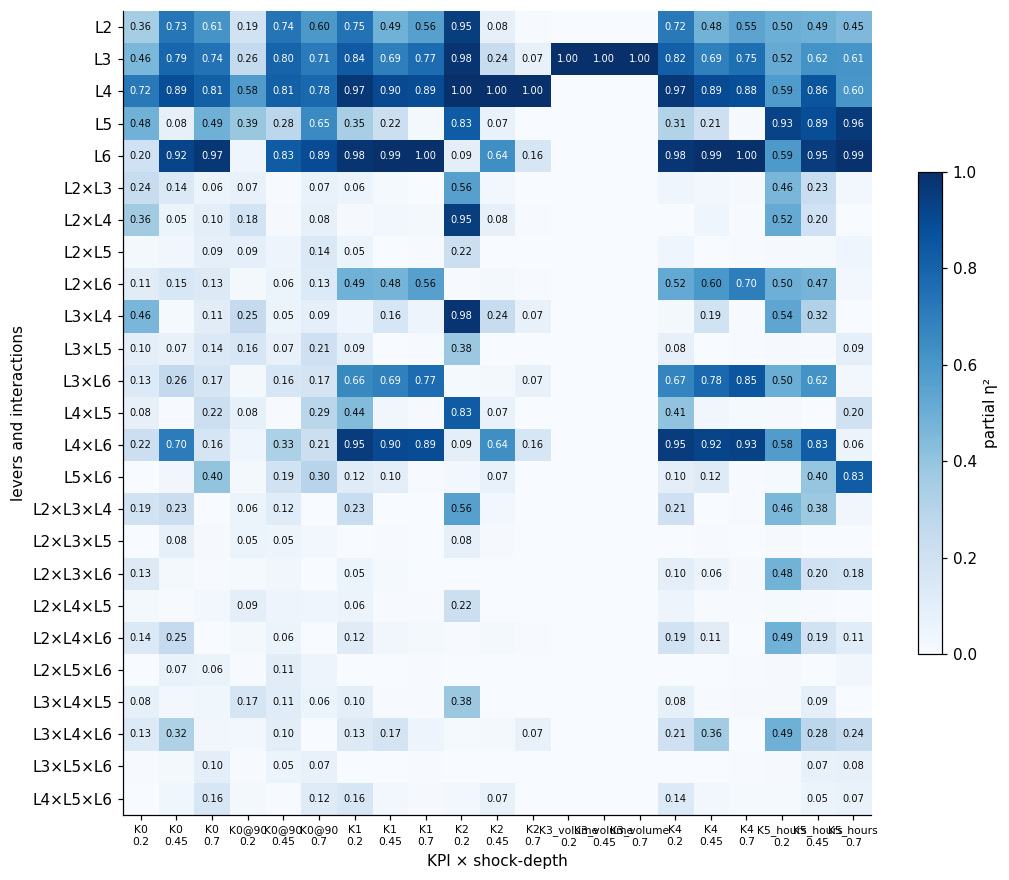

In [ ]:
piv = EFFECTS.pivot_table(index="term", columns=["KPI", "shock"], values="eta2_partial")
piv = piv.reindex(columns=pd.MultiIndex.from_product([[k for k in RESP if k in piv.columns.get_level_values(0)], SHOCKS]))
keep = piv.max(axis=1) >= ETA2_MIN
piv = piv[keep]

piv = piv.loc[sorted(piv.index, key=lambda t: (t.count("×"), t))]
fig, ax = plt.subplots(figsize=(1.0 + 0.42 * piv.shape[1], 0.6 + 0.3 * piv.shape[0]))
im = ax.imshow(piv.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(piv)), piv.index)
ax.set_xticks(range(piv.shape[1]), [f"{k}\n{s}" for k, s in piv.columns], fontsize=7)
for i in range(piv.shape[0]):  
    for j in range(piv.shape[1]):
        v = piv.iat[i, j]
        if np.isfinite(v) and v >= ETA2_MIN:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if v > 0.6 else "#0b0b0b")
            
ax.grid(False); fig.colorbar(im, ax=ax, label="partial η²", shrink=0.6)
ax.set_ylabel("levers and interactions"); ax.set_xlabel("KPI × shock-depth")
plt.tight_layout(); plt.show()

The main insight from the heatmap: K2 and K3 are deterministic and defined by L4 and L3 respectively. The values are 1.00, shown as deep blue lines. So basically L3 and L4 are those levers who produce their own KPIs. Still, we cannot ignore these levels nor KPIs. K2 and K3 carry valuable information about the costs and will be used in the next stages in cost formulation. L3 L4 have many dark lines part from its own KPI, L4×L6 has a strong effect that is impossible to ignore

Other insights mostly repeat the ones we noted earlier, making it more clear thanks to concise visualization:
- L4×L6 combo
- L3×L6 L2×L6 - more on those later
- triple interactions also are visible on the heat map, which again justifies our decision

## 1.9. Interaction plots of the screening results

Here we create interaction plots for the most important pairwise lever interactions. The top-3 interactions are selected by the maximum partial η² across K0 and K4 at shock = 0.45 (the central shock level). For each selected pair, the plot shows the geometric mean of the KPI when lever X is off/on, with separate lines for lever Y (off/on), across all shock levels. Parallel lines indicate no interaction; diverging slopes indicate that the effect of X depends on Y. Note that although selection uses K0 and K4, the plots display K0, K1, K4, and K5_hours by default; the KPI list and the interaction list can both be overridden manually.



most important pairwise interactions: ['L4×L6', 'L3×L6', 'L2×L6']


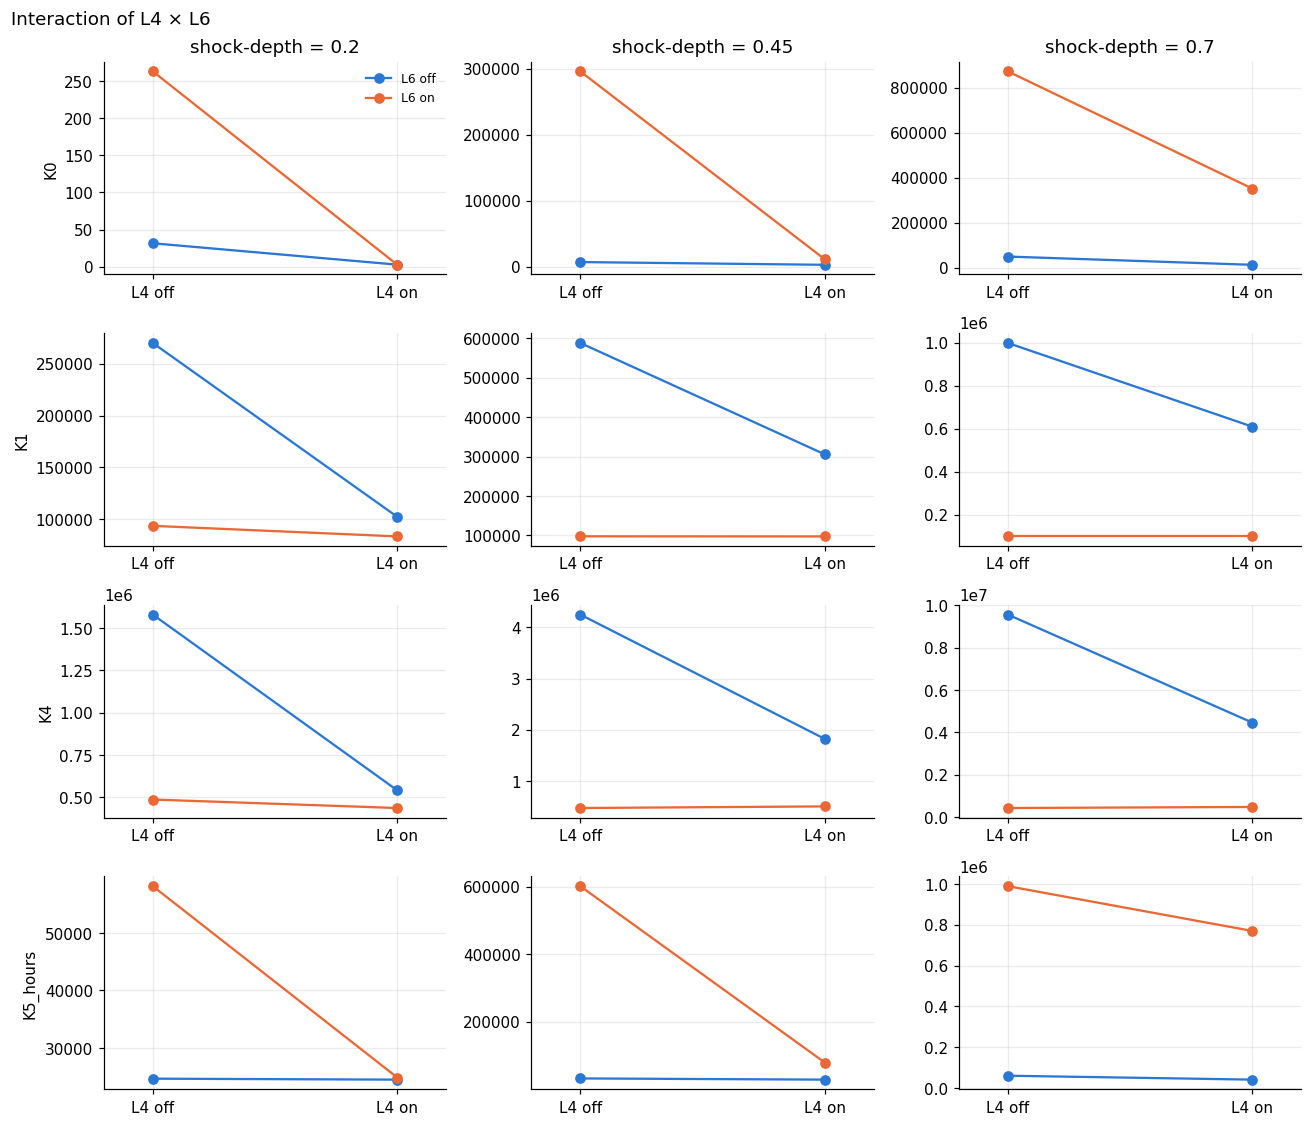

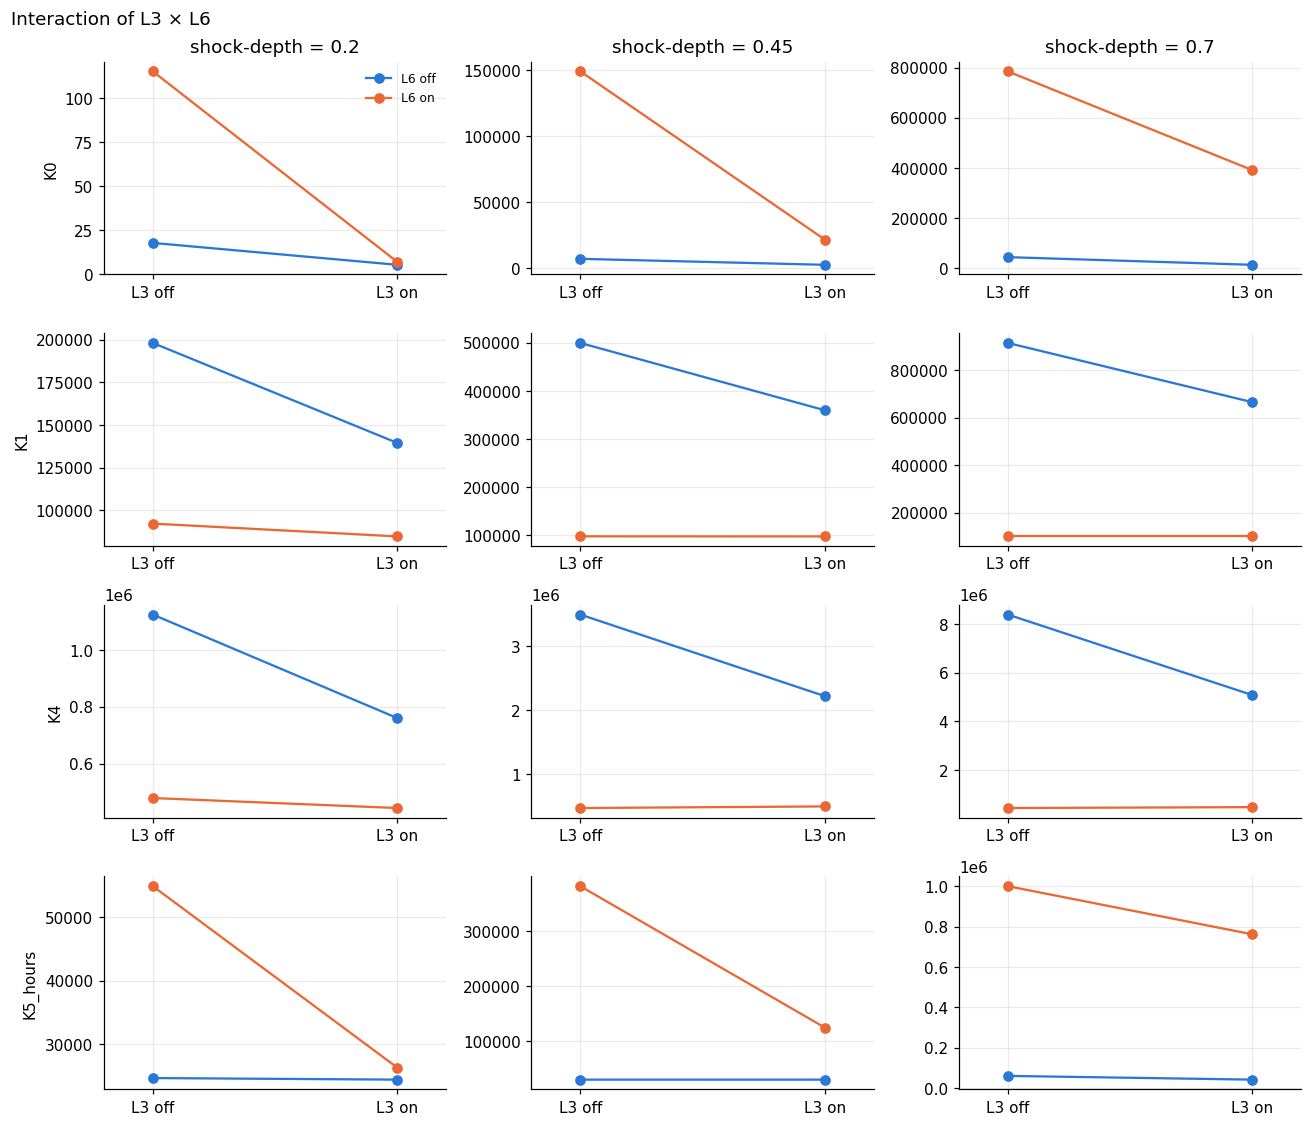

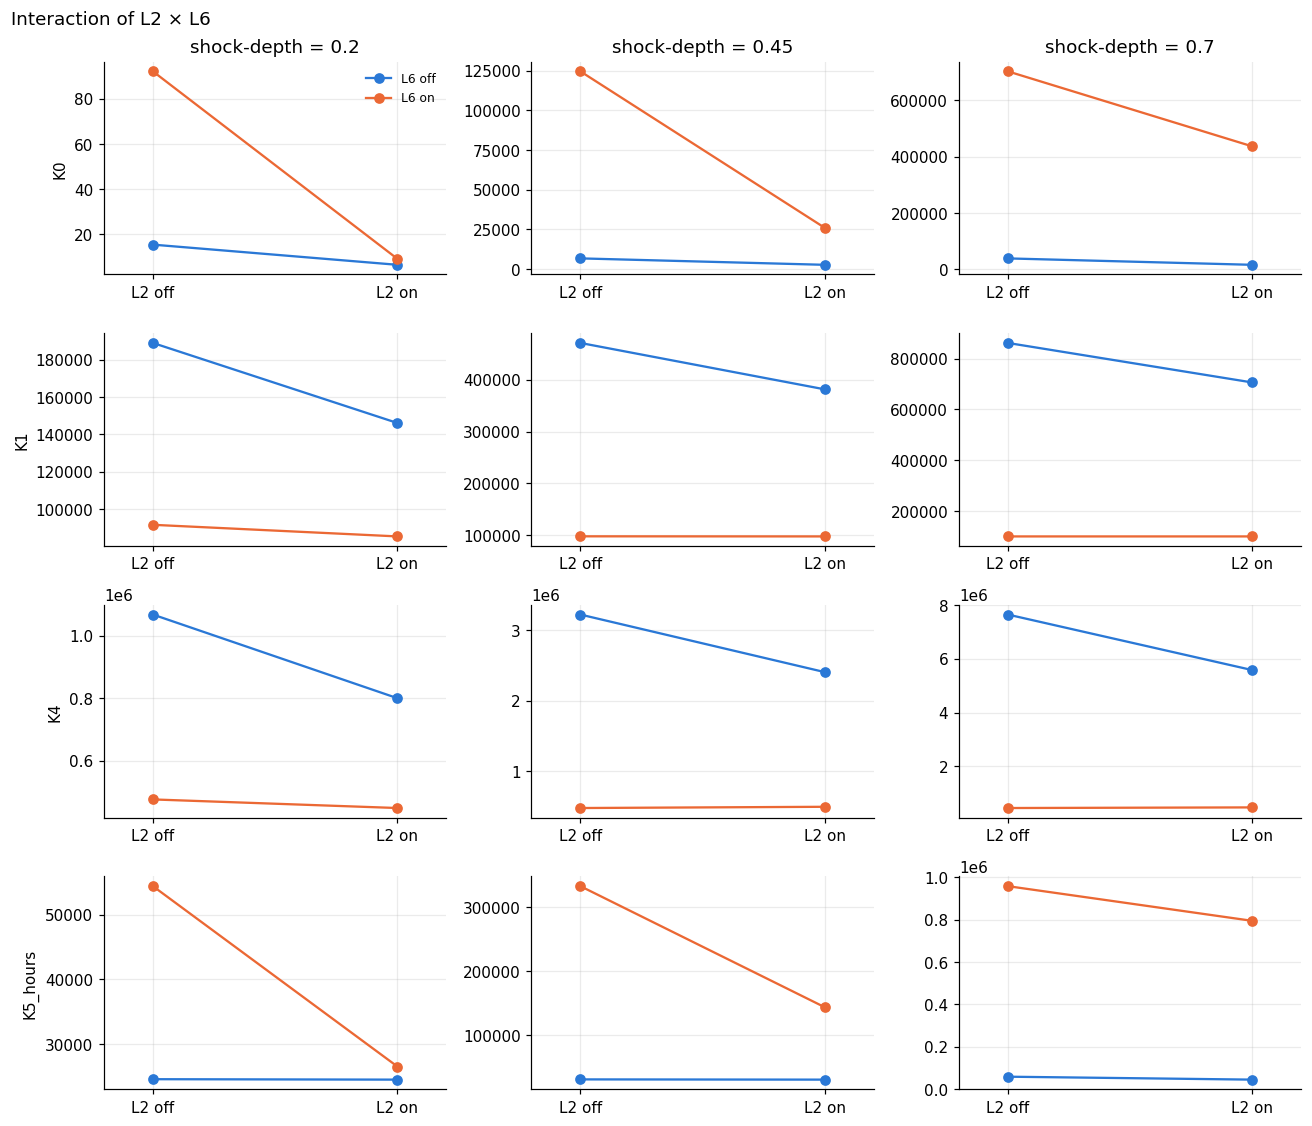

In [ ]:
def gmean_by(d, cols, kpi):
    """This function calculates the geometric mean of a specified KPI,
    grouped by the provided columns."""
    # retrieve the original scale of the KPI from the log-transformed values with np.expm1
    return d.groupby(cols)["log_" + kpi].mean().pipe(np.expm1)

def interaction_plot(x, y, kpis=("K0", "K1", "K4", "K5_hours")):
    
    """This function creates interaction plots for the specified levers (x and y) and KPIs.
    
    Parameters:
        x (str): The first lever to plot on the x-axis.
        y (str): The second lever to plot as separate lines.
        kpis (tuple): A tuple of KPIs to plot (default is ("K0", "K1", "K4", "K5_hours")).
    
    Returns:
        None: Displays the interaction plots for the specified levers and KPIs.
    
    """
    
    fig, axes = plt.subplots(len(kpis), 3, figsize=(12, 2.6 * len(kpis)), squeeze=False)
    for i, k in enumerate(kpis):
        for j, sh in enumerate(SHOCKS):
            ax = axes[i, j]
            g = gmean_by(SCR[SCR.shock == sh], [y, x], k)
            for c, lev in zip([PAL[0], PAL[1]], [-1, 1]):
                ax.plot([0, 1], [g.loc[(lev, -1)], g.loc[(lev, 1)]], "-o", color=c, ms=6,
                        label=f"{y} {'on' if lev == 1 else 'off'}")
            ax.set_xticks([0, 1], [f"{x} off", f"{x} on"]); ax.set_xlim(-0.2, 1.2)
            if i == 0: ax.set_title(f"shock-depth = {sh}")
            if j == 0: ax.set_ylabel(k)
    axes[0, 0].legend(frameon=False, fontsize=8)
    
    fig.suptitle(f"Interaction of {x} × {y}", x=0.01, ha="left"); plt.tight_layout(); plt.show()

# define most important pairwise interactions
# based on η² values for shock 0.45 and KPIs K0 and K4
top2 = (EFFECTS.query("order == 2 and shock == 0.45 and KPI in ['K0', 'K4']")
        .groupby("term").eta2_partial.max().nlargest(3).index.tolist())

print("most important pairwise interactions:", top2)
for t in top2:
    a, b = t.split("×")
    interaction_plot(a, b)

Domino effect of L6: price cap as the dominant lever. It can be observed by the L6 on/off gap on any of those 3 plots

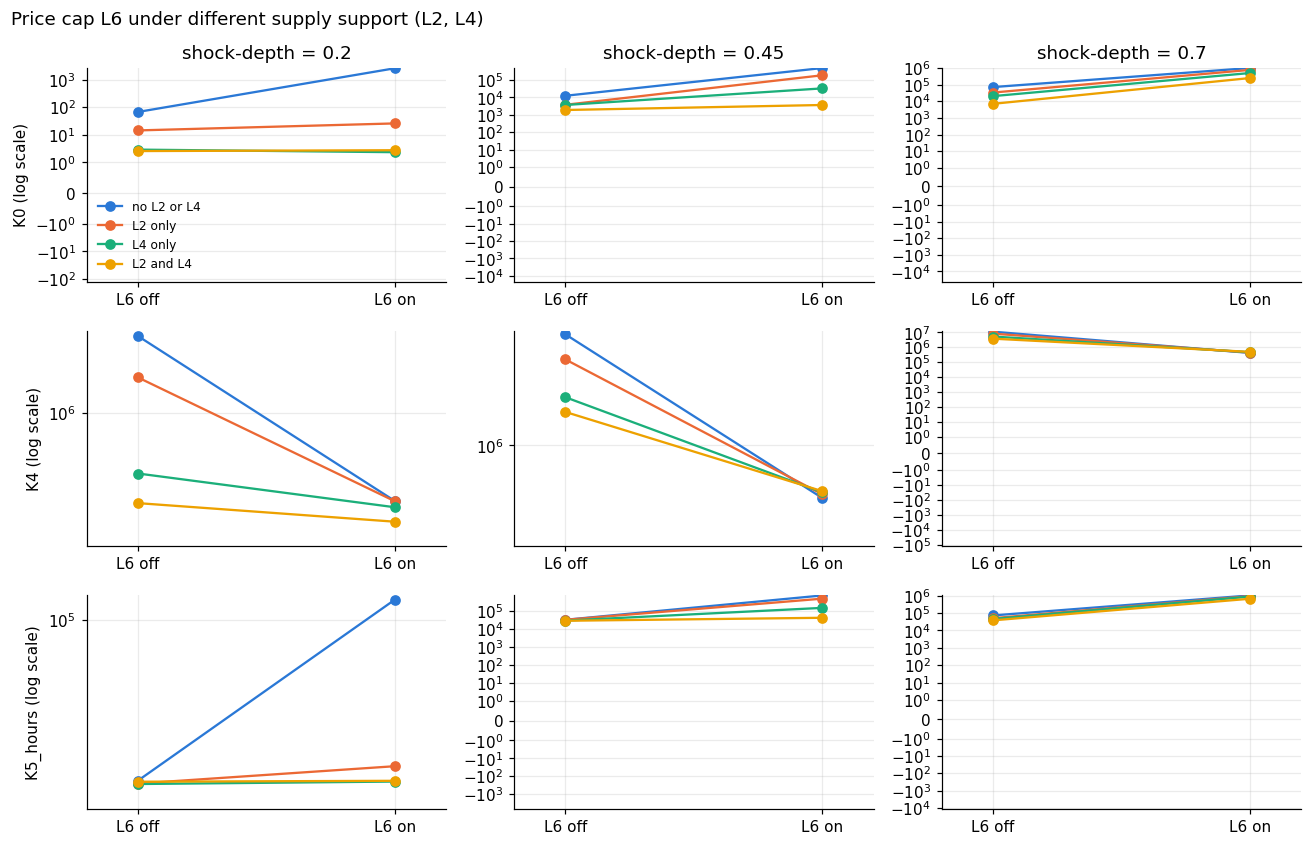

In [21]:
# Triple interaction L6 x L2 x L4: price cap effect under different supply support
def triple_plot(kpis=("K0", "K4", "K5_hours")):
    fig, axes = plt.subplots(len(kpis), 3, figsize=(
        12, 2.6 * len(kpis)), squeeze=False)
    for i, k in enumerate(kpis):
        for j, sh in enumerate(SHOCKS):
            ax = axes[i, j]
            g = gmean_by(SCR[SCR.shock == sh], ["L2", "L4", "L6"], k)
            for c, (l2, l4) in zip(PAL, [(-1, -1), (1, -1), (-1, 1), (1, 1)]):
                lbl = {(-1, -1): "no L2 or L4", (1, -1): "L2 only",
                       (-1, 1): "L4 only", (1, 1): "L2 and L4"}[(l2, l4)]
                ax.plot([0, 1], [g.loc[(l2, l4, -1)], g.loc[(l2, l4, 1)]],
                        "-o", color=c, ms=6, label=lbl)
            ax.set_xticks([0, 1], ["L6 off", "L6 on"])
            ax.set_xlim(-0.2, 1.2)
            ax.set_yscale("symlog", linthresh=1)
            if i == 0:
                ax.set_title(f"shock-depth = {sh}")
            if j == 0:
                ax.set_ylabel(f"{k} (log scale)")
    axes[0, 0].legend(frameon=False, fontsize=8)

    fig.suptitle(
        "Price cap L6 under different supply support (L2, L4)", x=0.01, ha="left")
    plt.tight_layout()
    plt.show()


triple_plot()

## 1.10. Checking model assumptions


In the cell below, we will select the most important levers based on the η² values calculated in the previous section. We will create a summary table that shows the maximum η² value for each lever across all KPIs and shock levels, as well as the maximum η² value for the main effect of each lever. We will also indicate whether to keep the lever based on whether its maximum η² value is greater than or equal to a predefined threshold (ETA2_MIN).


In [ ]:

sel = []
for l in LEVERS:
    e = EFFECTS[EFFECTS.term.str.split("×").apply(lambda parts: l in parts)]
    best = e.loc[e.eta2_partial.idxmax()]
    main = EFFECTS.query("term == @l")
    sel.append({"lever": l, "max η² (any term)": best.eta2_partial,
                "where": f"{best.term}, {best.KPI}, shock {best.shock}",
                "max η² of main effect": main.eta2_partial.max(),
                "keep": best.eta2_partial >= ETA2_MIN})
SELECTION = pd.DataFrame(sel)
SELECTION.to_csv(OUT_DIR / "screening_selection.csv", index=False, encoding="utf-8-sig")
SELECTION.round(3)

,lever,max η² (any term),where,max η² of main effect,keep
0,L2,0.948,"L2, K2, shock 0.2",0.948,True
1,L3,1.000,"L3, K3_volume, shock 0.2",1.000,True
2,L4,1.000,"L4, K2, shock 0.7",1.000,True
3,L5,0.959,"L5, K5_hours, shock 0.7",0.959,True
4,L6,0.998,"L6, K1, shock 0.7",0.998,True


During Pareto analysis we noticed that how L2 gives stable blue effects for every shock level. We now should check how often combinations of other levers with L2 are better than without L2. That way we might make L2 always on and save the later stages from testing L2 combinations

In [ ]:
def paired_effect(lever, kpis=KP):
    """
    This function calculates the paired effect of a specified lever on the given KPIs.

    Parameters:
        lever (str): The lever for which the paired effect is calculated.
        kpis (list): A list of KPIs to analyze (default is KP).

    Returns:
        pd.DataFrame: A DataFrame containing the paired effect results, including

    """
    others = [l for l in LEVERS if l != lever]
    idx = ["shock", "seed"] + others
    # with lever
    on = SCR[SCR[lever] == 1].set_index(idx)[kpis].sort_index()
    # without 
    off = SCR[SCR[lever] == -1].set_index(idx)[kpis].sort_index()
    # calculate the log ratio of the KPIs with and without the lever
    lr = np.log1p(on) - np.log1p(off.loc[on.index])
    rows = []
    for key, g in lr.groupby(level=["shock"] + others):
        sh, lev = key[0], key[1:]
        combo = "+".join(l for l, v in zip(others, lev) if v == 1) or "none"
        for k in kpis:
            x = g[k].to_numpy()
            m = x.mean()
            
            # using paired t-test
            h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / \
                np.sqrt(len(x)) if x.std() > 0 else 0.0
            
            # better worse or not significant based on the confidence interval
            verdict = "lever better" if m + \
                h < 0 else ("lever worse" if m - h > 0 else "not significant")
            
            
            rows.append({"lever": lever, "shock": sh, "other_levers": combo, "KPI": k,
                         "effect_%": 100 * (np.exp(m) - 1), "ci_low_%": 100 * (np.exp(m - h) - 1),
                         "ci_high_%": 100 * (np.exp(m + h) - 1), "verdict": verdict})
    return pd.DataFrame(rows)

In [ ]:
KP = ["K0", "K1", "K2", "K3_volume", "K4", "K5_hours"]

P2 = paired_effect("L2")
print("L2 vs no L2: count of verdicts by KPI and shock (16 combinations each)")
# show how many combinations of other levers are significantly better, worse, or not significant for each KPI and shock level
display(P2.pivot_table(index=["KPI", "verdict"], columns="shock", values="effect_%", aggfunc="count", fill_value=0))
print("L2 effect on K0 (range over combinations, %):")
# show the minimum, median, and maximum effect of L2 on K0 for each shock level
display(P2[P2.KPI == "K0"].groupby("shock")["effect_%"].describe()[["min", "50%", "max"]].round(1))


L2 vs no L2: count of verdicts by KPI and shock (16 combinations each)


shock                      0.20  0.45  0.70
KPI       verdict                          
K0        lever better        4    16    15
          not significant    12     0     1
K1        lever better       15    16     8
          not significant     1     0     8
K2        lever better        8     3     0
          lever worse         0     1     1
          not significant     8    12    15
K3_volume not significant    16    16    16
K4        lever better       14    10     8
          lever worse         2     6     8
K5_hours  lever better        6    11    13
          lever worse         6     2     0
          not significant     4     3     3

L2 effect on K0 (range over combinations, %):


,min,50%,max
shock,,,
0.20,-100.0,-42.1,60.2
0.45,-98.6,-72.6,-16.6
0.70,-81.2,-43.2,-18.6


In [15]:
print("Cases where L2 is significantly WORSE:")
display(P2[P2.verdict == "lever worse"].sort_values(["KPI", "shock"]).round(1))

Cases where L2 is significantly WORSE:


,lever,shock,other_levers,KPI,effect_%,ci_low_%,ci_high_%,verdict
134,L2,0.4,L4+L5,K2,0.4,0.1,0.6,lever worse
230,L2,0.7,L4+L5,K2,0.2,0.0,0.4,lever worse
10,L2,0.2,L6,K4,3.8,3.0,4.6,lever worse
22,L2,0.2,L5+L6,K4,4.1,2.6,5.6,lever worse
106,L2,0.4,L6,K4,5.8,5.8,5.9,lever worse
118,L2,0.4,L5+L6,K4,5.8,5.7,5.8,lever worse
130,L2,0.4,L4+L6,K4,4.1,3.6,4.7,lever worse
142,L2,0.4,L4+L5+L6,K4,3.8,2.8,4.8,lever worse
154,L2,0.4,L3+L6,K4,5.3,5.3,5.4,lever worse
166,L2,0.4,L3+L5+L6,K4,5.3,5.2,5.3,lever worse


L2 significantly reduces the physical shortage (K0) in all 16 lever combinations under a shock of 0.45 (median −73%) and in 15 of 16 under a shock of 0.7 (median −43%), and in no combination does it significantly increase it; K1 is never worsened either. 

The costs are limited: with a price cap (L6), overpayment K4 rises by 4–6%, because the capped price stays above the reference level while L2 adds volume sold; queues grow by 1–3% under a weak shock and by 8–15% under a medium shock when no supply levers are active, and do not grow under a strong shock. Since the reduction in shortage, the primary purpose of crisis measures, is large and robust, while the costs are small and confined to specific KPIs and combinations, L2 is fixed as enabled in stages 2–5. Within the model the export ban is costless: lost export revenue and trade consequences are not part of K0–K5, so this conclusion holds only inside the model.

## 1.11. Summary of model assumptions

The KPIs are normalized for reading: K0, K1, K4 - the share from "none" at the same shock (1 = as without measures); K5 - hours per machine above the background; K2 - m.u.; K3 - liters of low-grade gasoline per liter of "none" deficit (crisis scale). A combination is **non-dominated** at a given shock if no other combination is better or equal to it in all six KPIs and strictly better in at least one. With six criteria, there will be many non-dominated combinations - this is normal for screening; the goal is to discard obviously bad ones.



In [19]:
OBJ = ["K0", "K1", "K2", "K3_volume", "K4", "K5_hours"]

def nondominated(F):
    F = np.asarray(F, float)
    nd = np.ones(len(F), bool)
    for i in range(len(F)):
        dom = np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)
        nd[i] = not dom.any()
    return nd

tabs = []
for sh in SHOCKS:
    c = CELL[CELL.shock == sh].copy()
    none = c[c.design_id == "none"].iloc[0]
    c["nondominated"] = nondominated(c[OBJ])
    c["K0_rel"] = c.K0 / none.K0 if none.K0 > 0 else np.nan
    c["K1_rel"] = c.K1 / none.K1
    c["K4_rel"] = c.K4 / none.K4
    c["K5_h_per_car"] = c.K5_excess
    c["K3_per_L_deficit"] = c.K3_volume / none.K0 if none.K0 > 0 else np.nan
    tabs.append(c)
COMBO_TABLE = pd.concat(tabs)
nd_count = COMBO_TABLE.groupby("design_id").nondominated.sum()
COMBO_TABLE["nd_shocks"] = COMBO_TABLE.design_id.map(nd_count)
COMBO_TABLE.to_csv(OUT_DIR / "screening_combos.csv", index=False, encoding="utf-8-sig")

dropped = nd_count[nd_count == 0].index.tolist()
print(f"dominated under all shocks ({len(dropped)}):", dropped)
cols = ["design_id", "K0_rel", "K1_rel", "K4_rel", "K5_h_per_car", "K2", "K3_per_L_deficit", "price", "nondominated", "nd_shocks"]
(COMBO_TABLE.query("shock == 0.45")[cols].sort_values(["nondominated", "K0_rel"], ascending=[False, True])
 .round(3).reset_index(drop=True))

dominated under all shocks (2): ['L3+L5', 'L5']


,design_id,K0_rel,K1_rel,K4_rel,K5_h_per_car,K2,K3_per_L_deficit,price,nondominated,nd_shocks
0,L2+L3+L4,0.031,0.320,0.217,-0.001,122725.924,11.581,1.234,True,3
1,L2+L3,0.046,0.533,0.401,0.497,0.000,11.581,1.471,True,3
2,L2+L3+L4+L6,0.054,0.117,0.072,0.501,124544.980,11.581,1.100,True,3
3,L2+L3+L4+L5,0.062,0.291,0.194,8.846,122993.323,11.581,1.246,True,3
4,L2+L3+L4+L5+L6,0.068,0.115,0.071,10.378,124695.841,11.581,1.100,True,3
5,L2+L4,0.069,0.402,0.287,0.026,123165.538,0.000,1.307,True,3
6,L2+L4+L5,0.075,0.344,0.236,9.620,124542.082,0.000,1.292,True,3
7,L3+L4,0.079,0.378,0.266,0.024,122770.788,11.581,1.264,True,3
8,L2+L4+L5+L6,0.086,0.115,0.071,11.641,125962.809,0.000,1.100,True,3
9,L2+L3+L5,0.088,0.488,0.359,11.420,0.000,11.581,1.476,True,2


## 1.12. Summary of the screening results

Saving `screening_summary.json`: which levers to keep for stage 2, which combinations are discarded, run time (for the budget of stages 2-3)


In [20]:
SUMMARY = {
    "created": time.strftime("%Y-%m-%d %H:%M"), "model_sha256": sha, "design": "full 2^5",
    "R": R, "seeds": SCR_SEEDS, "shocks": SHOCKS, "lever_on": LEVER_ON, "eta2_min": ETA2_MIN,
    "n_runs": int(len(SCR) + len(BG)), "sec_per_run_mean": float(SCR.sec.mean()),
    "n_workers": N_WORKERS, "runs_per_hour": RUNS_PER_HOUR, "k5_background": float(K5_BG),
    "levers_keep": SELECTION.loc[SELECTION["keep"], "lever"].tolist(),
    "levers_drop": SELECTION.loc[~SELECTION["keep"], "lever"].tolist(),
    "combos_dominated_everywhere": dropped,
    "top_terms": {f"{r.KPI} @ {r.shock}": r.term for r in EFFECTS.sort_values("eta2_partial", ascending=False)
                  .drop_duplicates(["KPI", "shock"]).itertuples()},
}
(OUT_DIR / "screening_summary.json").write_text(json.dumps(SUMMARY, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps({k: v for k, v in SUMMARY.items() if k != "top_terms"}, indent=1, ensure_ascii=False, default=float))

{
 "created": "2026-11-19 18:05",
 "model_sha256": "2b246166dc0c118265a926ba837fad5e54d133f1dc980da4569aabaff48f5379",
 "design": "full 2^5",
 "R": 5,
 "seeds": [
  347,
  164,
  159,
  797,
  98
 ],
 "shocks": [
  0.2,
  0.45,
  0.7
 ],
 "lever_on": {
  "L3-share-naphtha": 0.15,
  "L4-import-limit": 0.1,
  "L5-liters-per-fillup": 30.0,
  "L6-price-cap": 1.1
 },
 "eta2_min": 0.05,
 "n_runs": 485,
 "sec_per_run_mean": 22.48067748145889,
 "n_workers": 2,
 "runs_per_hour": 349.4823303599943,
 "k5_background": 13675.069866666832,
 "levers_keep": [
  "L2",
  "L3",
  "L4",
  "L5",
  "L6"
 ],
 "levers_drop": [],
 "combos_dominated_everywhere": [
  "L3+L5",
  "L5"
 ]
}
